# Module 02: Dataset Formatting and Sequence-Level Splitting for YOLO

**Objective.** This notebook converts the MOT16 annotations to the YOLO format and partitions the data into training and validation sets.

### Data Splitting Strategy

The split is made at the sequence level rather than the frame level. Consecutive video frames are nearly identical, so a frame-level split would leak training content into the validation set and inflate the reported results.

| Partition | Sequences |
|---|---|
| Training | MOT16-02, 04, 05, 10, 11, 13 |
| Validation | MOT16-09 |

### Annotation Mapping & Filtering Rules

Only pedestrian annotations (`class == 1`) that the benchmark includes in its evaluation (`conf == 1`) are retained. Each box is converted to a normalized center-based format and assigned to a single class (`0 = person`).

**Verification.** The notebook confirms that image and label counts match, that no sequence appears in both partitions, and that the converted labels align with the source images.

In [ ]:
# 1. Set up, path, and check train and test dataset
!pip -q install ultralytics
from pathlib import Path

CANDIDATES = [Path('/content/drive/MyDrive/MOT16_project/Backup'),
              Path('/content/drive/MyDrive/MOT16_project/DL_Video_Tracking ')]     # trailing space is intentional
BASE = next((p for p in CANDIDATES if (p/'yolo_mot16.zip').exists()), None)
assert BASE, 'yolo_mot16.zip not found on Drive - run notebook 02 (step 7) first'

OUT = Path('/content/yolo_mot16')
if not (OUT/'images'/'val').exists():
    import shutil; shutil.unpack_archive(str(BASE/'yolo_mot16.zip'), '/content')
# the yaml stores an absolute path; rewrite it so it is correct in this session
yaml_path = OUT/'data.yaml'
yaml_path.write_text(f'path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n  0: person\n')
print('train imgs:', len(list((OUT/'images'/'train').glob('*.jpg'))),
      '| val imgs:', len(list((OUT/'images'/'val').glob('*.jpg'))))

RUNS = BASE/'runs'          # checkpoints live on Drive so a disconnect does not lose them
RUNS.mkdir(exist_ok=True)
RESULTS = BASE/'results'; RESULTS.mkdir(exist_ok=True)

In [ ]:
# 2. Config
import configparser
TRAIN_SEQS = ['MOT16-02','MOT16-04','MOT16-05','MOT16-10','MOT16-11','MOT16-13']
VAL_SEQS   = ['MOT16-09']
assert not set(TRAIN_SEQS) & set(VAL_SEQS)        # no overlap, ever

TRAIN_STRIDE = 2     # keep every 2nd train frame (consecutive frames are near-duplicates; halves size/time). Set 1 for all frames.
VAL_STRIDE   = 1
MIN_VIS      = 0.0   # drop heavily occluded boxes below this visibility (try 0.25 later as an experiment)
OUT = Path('/content/yolo_mot16')

In [ ]:
# 3. Converter
import shutil, pandas as pd
from tqdm import tqdm

def read_seqinfo(seq_dir):
    cp = configparser.ConfigParser(); cp.read(seq_dir/'seqinfo.ini')
    s = cp['Sequence']
    return int(s['imWidth']), int(s['imHeight']), int(s['seqLength'])

def convert_sequence(seq, split, stride):
    seq_dir = ROOT/'train'/seq
    W, H, n = read_seqinfo(seq_dir)
    gt = pd.read_csv(seq_dir/'gt'/'gt.txt', header=None,
                     names=['frame','id','x','y','w','h','conf','cls','vis'])
    gt = gt[(gt.cls == 1) & (gt.conf == 1) & (gt.vis >= MIN_VIS)]
    img_out, lbl_out = OUT/'images'/split, OUT/'labels'/split
    img_out.mkdir(parents=True, exist_ok=True); lbl_out.mkdir(parents=True, exist_ok=True)

    by_frame = {f: g for f, g in gt.groupby('frame')}
    n_img = n_box = 0
    for f in range(1, n + 1, stride):
        name = f'{seq}_{f:06d}'
        shutil.copy(seq_dir/'img1'/f'{f:06d}.jpg', img_out/f'{name}.jpg')
        lines = []
        for r in by_frame.get(f, pd.DataFrame()).itertuples():
            # clip to image, then convert top-left xywh (pixels) -> normalized center xywh
            x1, y1 = max(r.x, 0), max(r.y, 0)
            x2, y2 = min(r.x + r.w, W), min(r.y + r.h, H)
            if x2 - x1 < 2 or y2 - y1 < 2: continue
            lines.append(f'0 {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}')
        (lbl_out/f'{name}.txt').write_text('\n'.join(lines))   # empty file = valid background image
        n_img += 1; n_box += len(lines)
    return n_img, n_box

shutil.rmtree(OUT, ignore_errors=True)
stats = {}
for split, seqs, stride in [('train', TRAIN_SEQS, TRAIN_STRIDE), ('val', VAL_SEQS, VAL_STRIDE)]:
    for seq in tqdm(seqs, desc=split):
        stats[(split, seq)] = convert_sequence(seq, split, stride)

for (split, seq), (ni, nb) in stats.items():
    print(f'{split:5s} {seq}: {ni:5d} images, {nb:7d} boxes ({nb/max(ni,1):.1f}/img)')

val: 100%|██████████| 1/1 [00:01<00:00,  1.66s/it]

train MOT16-02:   300 images,    8917 boxes (29.7/img)
train MOT16-04:   525 images,   23772 boxes (45.3/img)
train MOT16-05:   419 images,    3419 boxes (8.2/img)
train MOT16-10:   327 images,    6157 boxes (18.8/img)
train MOT16-11:   450 images,    4592 boxes (10.2/img)
train MOT16-13:   375 images,    5729 boxes (15.3/img)
val   MOT16-09:   525 images,    5257 boxes (10.0/img)


In [ ]:
# 4. data.yaml
yaml_path = OUT/'data.yaml'
yaml_path.write_text(f'path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n  0: person\n')
print(yaml_path.read_text())

path: /content/yolo_mot16
train: images/train
val: images/val
names:
  0: person



In [ ]:
# 5. Sanity checks: counts match, no leakage, labels in range
tr = sorted((OUT/'images'/'train').glob('*.jpg')); va = sorted((OUT/'images'/'val').glob('*.jpg'))
trl = list((OUT/'labels'/'train').glob('*.txt'));  val_ = list((OUT/'labels'/'val').glob('*.txt'))
print('train images/labels:', len(tr), len(trl), '| val images/labels:', len(va), len(val_))
assert len(tr) == len(trl) and len(va) == len(val_)
assert not ({p.name.split('_')[0] for p in tr} & {p.name.split('_')[0] for p in va}), 'LEAKAGE'
bad = 0
for p in trl + val_:
    for ln in p.read_text().splitlines():
        c, x, y, w, h = ln.split(); vals = list(map(float, (x, y, w, h)))
        if c != '0' or any(v < 0 or v > 1 for v in vals): bad += 1
print('out-of-range label lines:', bad)
print('train sequences:', sorted({p.name.rsplit('_',1)[0] for p in tr}))
print('val sequences  :', sorted({p.name.rsplit('_',1)[0] for p in va}))

train images/labels: 2396 2396 | val images/labels: 525 525
out-of-range label lines: 0
train sequences: ['MOT16-02', 'MOT16-04', 'MOT16-05', 'MOT16-10', 'MOT16-11', 'MOT16-13']
val sequences  : ['MOT16-09']


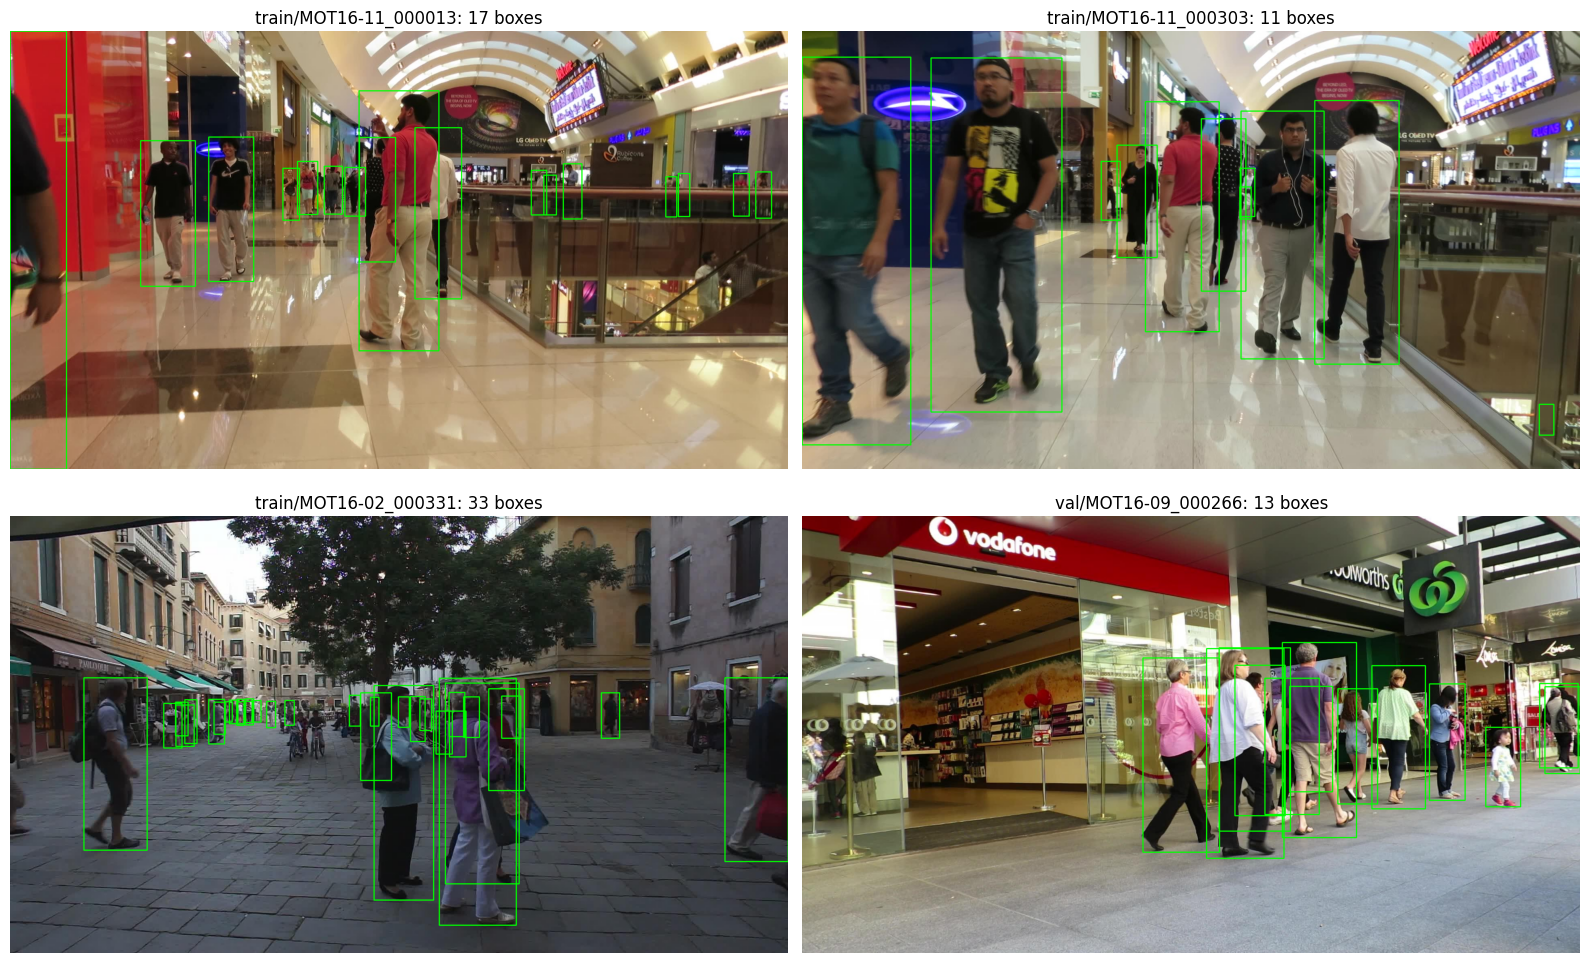

In [ ]:
# 6. Visual check: converted labels drawn back onto images (boxes must sit on people)
import cv2, matplotlib.pyplot as plt, random
random.seed(0)
samples = random.sample(tr, 3) + random.sample(va, 1)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, p in zip(axes.ravel(), samples):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    lbl = (OUT/'labels'/p.parent.name/f'{p.stem}.txt').read_text().splitlines()
    for ln in lbl:
        _, cx, cy, w, h = map(float, ln.split())
        x1, y1, x2, y2 = int((cx-w/2)*W), int((cy-h/2)*H), int((cx+w/2)*W), int((cy+h/2)*H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    ax.imshow(img); ax.set_title(f'{p.parent.name}/{p.stem}: {len(lbl)} boxes'); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# 7. Save a zip to Drive so a fresh Colab session can skip conversion
from pathlib import Path
DRIVE_MOT16 = Path('/content/drive/MyDrive/MOT16_project/Backup')
BACKUP = DRIVE_MOT16
!cd /content && zip -qr "{BACKUP}/yolo_mot16.zip" yolo_mot16
!ls -lh "{BACKUP}/yolo_mot16.zip"
# To restore later:  !unzip -q "{BACKUP}/yolo_mot16.zip" -d /content

-rw------- 1 root root 470M Oct 15 08:53 /content/drive/MyDrive/MOT16_project/Backup/yolo_mot16.zip


In [ ]:
# 8. (Optional) smoke test: does YOLO accept the dataset and train? 1 epoch on 5% of data, NOT a real run
from ultralytics import YOLO
model = YOLO('yolo26m.pt')    # fallback: 'yolo11m.pt'
model.train(data=str(yaml_path), epochs=1, imgsz=960, batch=8, fraction=0.05,
            project='/content/runs', name='smoke', workers=2, plots=False)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_mot16/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke, nbs=64, nms=None, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f1b3a3afed0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 